# TP7 — Prévision Multivariée Multi-Step avec LSTM & BiLSTM

**Objectif :** Prédire les valeurs moyennes de température, humidité et pression sur 12 horizons futurs.

In [46]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.19.0


---
## PARTIE I — Pipeline de prévision

---
### Q1 — Chargement du dataset, index temporel et sélection des variables d'entrée

In [47]:
# Téléchargement du dataset Jena Climate
url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'
zip_path = tf.keras.utils.get_file('jena_climate_2009_2016.csv.zip', origin=url, extract=False)

extract_dir = os.path.dirname(zip_path)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

csv_path = os.path.join(extract_dir, 'jena_climate_2009_2016.csv')
df = pd.read_csv(csv_path)

print('Taille initiale :', df.shape)
print(df.head())

Taille initiale : (420551, 15)
             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0 

In [48]:
# Préparation de l'index temporel
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df.set_index('Date Time', inplace=True)

print('Types de données :')
print(df.dtypes)
print('\nAperçu :')
print(df.head())

Types de données :
p (mbar)           float64
T (degC)           float64
Tpot (K)           float64
Tdew (degC)        float64
rh (%)             float64
VPmax (mbar)       float64
VPact (mbar)       float64
VPdef (mbar)       float64
sh (g/kg)          float64
H2OC (mmol/mol)    float64
rho (g/m**3)       float64
wv (m/s)           float64
max. wv (m/s)      float64
wd (deg)           float64
dtype: object

Aperçu :
                     p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
Date Time                                                                
2009-01-01 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
2009-01-01 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2009-01-01 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
2009-01-01 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
2009-01-01 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

                     VPmax (mbar)  VPact (mbar)  VPdef (mbar

In [49]:
# Sélection des variables d'entrée (6 variables météo)
feature_cols = [
    'T (degC)',       # Température
    'rh (%)',         # Humidité relative
    'p (mbar)',       # Pression
    'wv (m/s)',       # Vitesse du vent
    'max. wv (m/s)', # Vitesse maximale du vent
    'wd (deg)'        # Direction du vent
]

data = df[feature_cols].copy()
print('Taille du dataset global :', df.shape)
print('Taille du sous-dataset :', data.shape)

Taille du dataset global : (420551, 14)
Taille du sous-dataset : (420551, 6)


---
### Q2 — Rééchantillonnage horaire (agrégation par moyenne) et définition de X et Y

In [50]:
# Rééchantillonnage en fréquence horaire par MOYENNE
# (différence avec le cours qui utilisait mean/max/min : ici on utilise uniquement la moyenne)
data_hourly = data.resample('1H').mean()

print('\nTaille après resampling horaire :', data_hourly.shape)
print(data_hourly.head())


Taille après resampling horaire : (70129, 6)
                     T (degC)     rh (%)    p (mbar)  wv (m/s)  max. wv (m/s)  \
Date Time                                                                       
2009-01-01 00:00:00 -8.304000  93.780000  996.528000  0.520000       1.002000   
2009-01-01 01:00:00 -8.065000  93.933333  996.525000  0.316667       0.711667   
2009-01-01 02:00:00 -8.763333  93.533333  996.745000  0.248333       0.606667   
2009-01-01 03:00:00 -8.896667  93.200000  996.986667  0.176667       0.606667   
2009-01-01 04:00:00 -9.348333  92.383333  997.158333  0.290000       0.670000   

                       wd (deg)  
Date Time                        
2009-01-01 00:00:00  174.460000  
2009-01-01 01:00:00  172.416667  
2009-01-01 02:00:00  196.816667  
2009-01-01 03:00:00  157.083333  
2009-01-01 04:00:00  150.093333  


/tmp/ipykernel_4631/2679846358.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  data_hourly = data.resample('1H').mean()


In [51]:
# Variables d'entrée X : les 6 variables sélectionnées
feature_cols_hourly = data_hourly.columns.tolist()
print('Colonnes disponibles :', feature_cols_hourly)

# Variables cibles Y : valeurs moyennes de température, humidité et pression
target_cols = [
    'T (degC)',   # Température moyenne
    'rh (%)',     # Humidité moyenne
    'p (mbar)'    # Pression moyenne
]

X = data_hourly[feature_cols_hourly]
y = data_hourly[target_cols]

print('\nShape X :', X.shape)
print('Shape y :', y.shape)

Colonnes disponibles : ['T (degC)', 'rh (%)', 'p (mbar)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']

Shape X : (70129, 6)
Shape y : (70129, 3)


---
### Q3 — Vérification et traitement des valeurs manquantes

In [52]:
print('Valeurs manquantes dans data_hourly :')
print(data_hourly.isnull().sum())

Valeurs manquantes dans data_hourly :
T (degC)         88
rh (%)           88
p (mbar)         88
wv (m/s)         88
max. wv (m/s)    88
wd (deg)         88
dtype: int64


In [53]:
# Traitement : interpolation temporelle puis suppression des NaN restants
data_hourly = data_hourly.interpolate(method='time').dropna()

# Reconstruire X et y après nettoyage
X = data_hourly[feature_cols_hourly]
y = data_hourly[target_cols]

print('Taille après interpolation :', data_hourly.shape)
print('Nombre de NaN restants :')
print(data_hourly.isnull().sum())

Taille après interpolation : (70129, 6)
Nombre de NaN restants :
T (degC)         0
rh (%)           0
p (mbar)         0
wv (m/s)         0
max. wv (m/s)    0
wd (deg)         0
dtype: int64


---
### Q4 — Découpage train / validation / test (ordre temporel respecté)

In [54]:
n = len(X)

train_size = int(n * 0.70)
val_size   = int(n * 0.15)
test_size  = n - train_size - val_size

X_train_df = X.iloc[:train_size]
X_val_df   = X.iloc[train_size : train_size + val_size]
X_test_df  = X.iloc[train_size + val_size :]

y_train_df = y.iloc[:train_size]
y_val_df   = y.iloc[train_size : train_size + val_size]
y_test_df  = y.iloc[train_size + val_size :]

print('Shape X_train :', X_train_df.shape)
print('Shape X_val   :', X_val_df.shape)
print('Shape X_test  :', X_test_df.shape)
print('Shape y_train :', y_train_df.shape)
print('Shape y_val   :', y_val_df.shape)
print('Shape y_test  :', y_test_df.shape)

Shape X_train : (49090, 6)
Shape X_val   : (10519, 6)
Shape X_test  : (10520, 6)
Shape y_train : (49090, 3)
Shape y_val   : (10519, 3)
Shape y_test  : (10520, 3)


---
### Q5 — Normalisation séparée de X et Y

In [55]:
# Deux scalers distincts : un pour X, un pour Y
# Ajustés UNIQUEMENT sur le train pour éviter la fuite de données (data leakage)
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_df)
X_val_scaled   = scaler_X.transform(X_val_df)
X_test_scaled  = scaler_X.transform(X_test_df)

y_train_scaled = scaler_y.fit_transform(y_train_df)
y_val_scaled   = scaler_y.transform(y_val_df)
y_test_scaled  = scaler_y.transform(y_test_df)

print('Shape X_train_scaled :', X_train_scaled.shape)
print('Shape y_train_scaled :', y_train_scaled.shape)

Shape X_train_scaled : (49090, 6)
Shape y_train_scaled : (49090, 3)


---
### Q6 — Création des séquences temporelles (lookback=72, horizon=12)

In [56]:
lookback = 72   # 72 heures passées = 3 cycles journaliers
horizon  = 12   # prédire les 12 prochaines heures

def create_multivariate_sequences(X_data, y_data, lookback, horizon):
    """Crée des fenêtres glissantes pour la prévision multi-step multivariée."""
    X_seq, y_seq = [], []
    for i in range(len(X_data) - lookback - horizon + 1):
        X_window = X_data[i : i + lookback]           # (lookback, n_features)
        y_window = y_data[i + lookback : i + lookback + horizon]  # (horizon, n_targets)
        X_seq.append(X_window)
        y_seq.append(y_window)
    return np.array(X_seq), np.array(y_seq)

X_train, y_train = create_multivariate_sequences(X_train_scaled, y_train_scaled, lookback, horizon)
X_val,   y_val   = create_multivariate_sequences(X_val_scaled,   y_val_scaled,   lookback, horizon)
X_test,  y_test  = create_multivariate_sequences(X_test_scaled,  y_test_scaled,  lookback, horizon)

print('Shape X_train :', X_train.shape)
print('Shape y_train :', y_train.shape)
print('Shape X_val   :', X_val.shape)
print('Shape y_val   :', y_val.shape)
print('Shape X_test  :', X_test.shape)
print('Shape y_test  :', y_test.shape)

Shape X_train : (49007, 72, 6)
Shape y_train : (49007, 12, 3)
Shape X_val   : (10436, 72, 6)
Shape y_val   : (10436, 12, 3)
Shape X_test  : (10437, 72, 6)
Shape y_test  : (10437, 12, 3)


---
### Q7 — Interprétation des dimensions des tenseurs

In [57]:
n_features = X_train.shape[2]
n_targets  = y_train.shape[2]

print('=== Dimensions des tenseurs ===')
print(f'X_train : {X_train.shape}')
print(f'  → {X_train.shape[0]} séquences, {X_train.shape[1]} pas de temps (lookback), {X_train.shape[2]} variables d\'entrée')
print(f'y_train : {y_train.shape}')
print(f'  → {y_train.shape[0]} séquences, {y_train.shape[1]} horizons futurs, {y_train.shape[2]} variables cibles')
print(f'\nn_features = {n_features} | n_targets = {n_targets} | horizon = {horizon}')

=== Dimensions des tenseurs ===
X_train : (49007, 72, 6)
  → 49007 séquences, 72 pas de temps (lookback), 6 variables d'entrée
y_train : (49007, 12, 3)
  → 49007 séquences, 12 horizons futurs, 3 variables cibles

n_features = 6 | n_targets = 3 | horizon = 12


**Interprétation :**
- `X_train` a la forme `(n_samples, lookback, n_features)` = `(N, 72, 6)` : pour chaque exemple, on fournit 72 heures de 6 variables.
- `y_train` a la forme `(n_samples, horizon, n_targets)` = `(N, 12, 3)` : pour chaque exemple, on prédit 12 heures futures pour 3 variables.
- Le lookback de 72h couvre 3 cycles journaliers complets, ce qui permet au modèle de capturer la saisonnalité journalière.

---
### Q8 — Aplatissement de la sortie Y pour Keras (Dense layer)

In [58]:
# La couche Dense de Keras ne peut produire qu'un vecteur 1D.
# Or y est de forme (n, horizon, n_targets) = (n, 12, 3).
# On l'aplatit donc en (n, 12*3) = (n, 36).

y_train_flat = y_train.reshape((y_train.shape[0], horizon * n_targets))
y_val_flat   = y_val.reshape((y_val.shape[0],   horizon * n_targets))
y_test_flat  = y_test.reshape((y_test.shape[0],  horizon * n_targets))

print('Shape y_train_flat :', y_train_flat.shape)
print('Shape y_val_flat   :', y_val_flat.shape)
print('Shape y_test_flat  :', y_test_flat.shape)
print(f'\n→ horizon × n_targets = {horizon} × {n_targets} = {horizon * n_targets} sorties par séquence')

Shape y_train_flat : (49007, 36)
Shape y_val_flat   : (10436, 36)
Shape y_test_flat  : (10437, 36)

→ horizon × n_targets = 12 × 3 = 36 sorties par séquence


---
### Q9 — Construction et entraînement des modèles LSTM et BiLSTM

In [59]:
from tensorflow.keras.layers import Bidirectional, Dropout

# ── Modèle LSTM ────────────────────────────────────────────────
def build_lstm_model(lookback, n_features, horizon, n_targets):
    model = Sequential([
        LSTM(64, input_shape=(lookback, n_features)),
        Dropout(0.2),
        Dense(horizon * n_targets)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

# ── Modèle BiLSTM ───────────────────────────────────────────────
def build_bilstm_model(lookback, n_features, horizon, n_targets):
    model = Sequential([
        Bidirectional(LSTM(64), input_shape=(lookback, n_features)),
        Dropout(0.2),
        Dense(horizon * n_targets)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

lstm_model   = build_lstm_model(lookback, n_features, horizon, n_targets)
bilstm_model = build_bilstm_model(lookback, n_features, horizon, n_targets)

print('\nRésumé modèle LSTM :')
lstm_model.summary()
print('\nRésumé modèle BiLSTM :')
bilstm_model.summary()


Résumé modèle LSTM :


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,516 (80.14 KB)

 Trainable params: 20,516 (80.14 KB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        36,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,996 (160.14 KB)

 Trainable params: 40,996 (160.14 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# EarlyStopping distinct pour chaque modèle
early_stop_lstm = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

early_stop_bilstm = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

print('Entraînement du modèle LSTM...')
history_lstm = lstm_model.fit(
    X_train, y_train_flat,
    validation_data=(X_val, y_val_flat),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop_lstm],
    verbose=1
)

Entraînement du modèle LSTM...
Epoch 1/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0285 - val_loss: 0.0066
Epoch 2/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0094 - val_loss: 0.0059
Epoch 3/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0076 - val_loss: 0.0058
Epoch 4/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0066 - val_loss: 0.0057
Epoch 5/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0059 - val_loss: 0.0055
Epoch 6/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0054 - val_loss: 0.0055
Epoch 7/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0050 - val_loss: 0.0055
Epoch 8/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0047 - val_loss: 0.0051
Epoch 9/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0046 - val_loss: 0.0050
Epoch 10/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0044 - val_loss: 0.0049
Epoch 11/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0043 - val_loss: 0.0048
Epoch 12/30
766/766 ━

In [61]:
print('Entraînement du modèle BiLSTM...')
history_bilstm = bilstm_model.fit(
    X_train, y_train_flat,
    validation_data=(X_val, y_val_flat),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop_bilstm],
    verbose=1
)

Entraînement du modèle BiLSTM...
Epoch 1/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.0200 - val_loss: 0.0061
Epoch 2/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 0.0079 - val_loss: 0.0054
Epoch 3/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 0.0065 - val_loss: 0.0050
Epoch 4/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.0058 - val_loss: 0.0048
Epoch 5/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 0.0054 - val_loss: 0.0046
Epoch 6/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0051 - val_loss: 0.0045
Epoch 7/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 0.0048 - val_loss: 0.0045
Epoch 8/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.0046 - val_loss: 0.0044
Epoch 9/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0045 - val_loss: 0.0044
Epoch 10/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 11/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 

---
### Q10 — Courbes d'apprentissage (loss et val_loss)

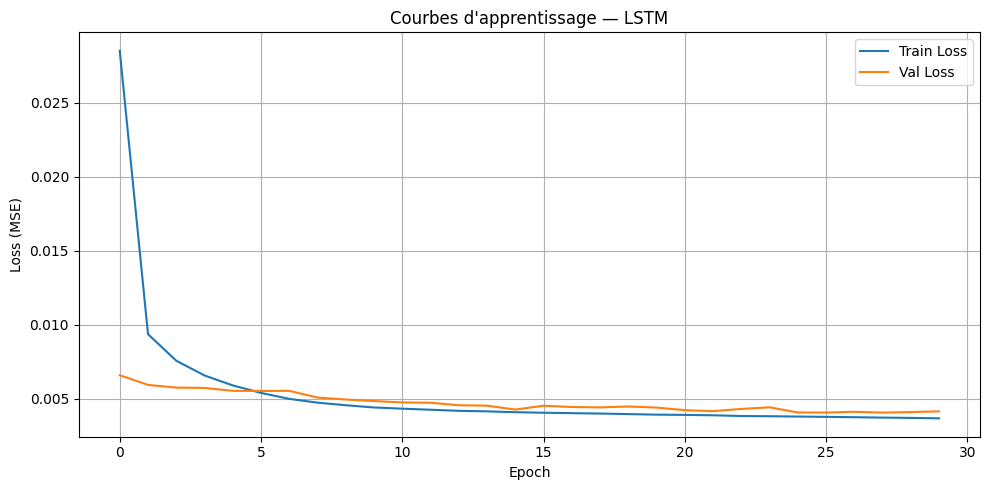

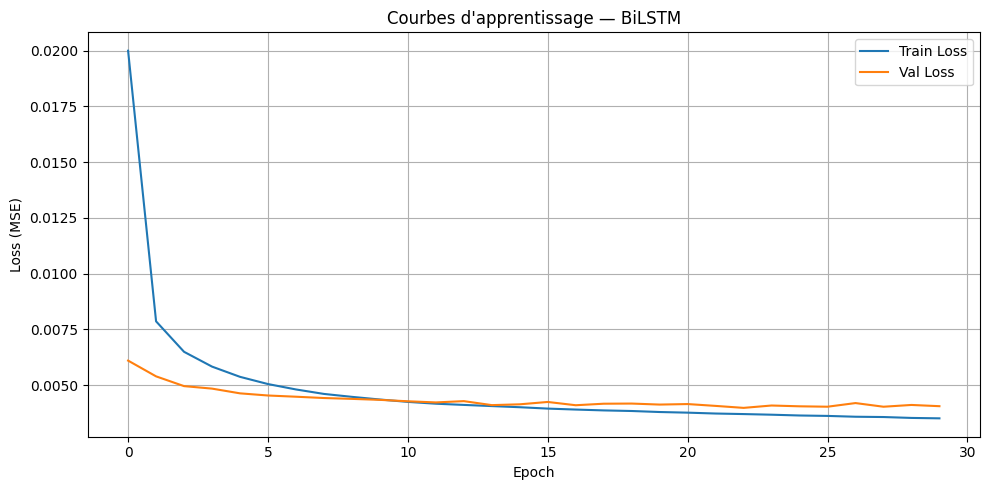

In [62]:
def plot_history(history, title):
    plt.figure(figsize=(10, 5))
    plt.plot(history.history['loss'],     label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_history(history_lstm,   'Courbes d\'apprentissage — LSTM')
plot_history(history_bilstm, 'Courbes d\'apprentissage — BiLSTM')

**Interprétation :** Les deux courbes montrent une descente rapide de la loss durant les premières epochs, puis une stabilisation. La val_loss reste proche de la train_loss, ce qui indique une bonne généralisation sans sur-apprentissage prononcé. L'EarlyStopping a restauré les meilleurs poids obtenus.

---
### Q11 — Prédictions sur l'ensemble de test et réorganisation

In [63]:
# Prédictions (sorties aplaties)
y_pred_lstm_flat   = lstm_model.predict(X_test)
y_pred_bilstm_flat = bilstm_model.predict(X_test)

# Réorganisation vers la structure multi-step multivariée (n_samples, horizon, n_targets)
y_pred_lstm   = y_pred_lstm_flat.reshape((-1, horizon, n_targets))
y_pred_bilstm = y_pred_bilstm_flat.reshape((-1, horizon, n_targets))

print('Shape y_pred_lstm   :', y_pred_lstm.shape)
print('Shape y_pred_bilstm :', y_pred_bilstm.shape)
print('Shape y_test        :', y_test.shape)

327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
327/327 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Shape y_pred_lstm   : (10437, 12, 3)
Shape y_pred_bilstm : (10437, 12, 3)
Shape y_test        : (10437, 12, 3)


---
### Q12 — Inverse scaling (retour à l'échelle originale)

In [64]:
def inverse_transform_multistep(y_scaled, scaler_y):
    """Inverse scaling pour des données de forme (n_samples, horizon, n_targets)."""
    s, h, t = y_scaled.shape
    # Aplatir en 2D pour le scaler
    y_2d    = y_scaled.reshape((s * h, t))
    y_inv_2d = scaler_y.inverse_transform(y_2d)
    y_inv    = y_inv_2d.reshape((s, h, t))
    return y_inv

y_test_inv        = inverse_transform_multistep(y_test,        scaler_y)
y_pred_lstm_inv   = inverse_transform_multistep(y_pred_lstm,   scaler_y)
y_pred_bilstm_inv = inverse_transform_multistep(y_pred_bilstm, scaler_y)

print('Shape y_test_inv        :', y_test_inv.shape)
print('Shape y_pred_lstm_inv   :', y_pred_lstm_inv.shape)
print('Shape y_pred_bilstm_inv :', y_pred_bilstm_inv.shape)

Shape y_test_inv        : (10437, 12, 3)
Shape y_pred_lstm_inv   : (10437, 12, 3)
Shape y_pred_bilstm_inv : (10437, 12, 3)


---
### Q13 — Évaluation : MAE, RMSE, R² par horizon et par variable

In [65]:
def evaluate_multivariate_multistep(y_true, y_pred, model_name, target_cols):
    """Calcule MAE, RMSE, R² pour chaque horizon et chaque variable cible."""
    results = []
    for h in range(y_true.shape[1]):
        for j in range(y_true.shape[2]):
            true_hj = y_true[:, h, j]
            pred_hj = y_pred[:, h, j]
            mae  = mean_absolute_error(true_hj, pred_hj)
            rmse = np.sqrt(mean_squared_error(true_hj, pred_hj))
            r2   = r2_score(true_hj, pred_hj)
            results.append({
                'Model':    model_name,
                'Horizon':  h + 1,
                'Variable': target_cols[j],
                'MAE':      mae,
                'RMSE':     rmse,
                'R2':       r2
            })
    return pd.DataFrame(results)

df_lstm_scores   = evaluate_multivariate_multistep(y_test_inv, y_pred_lstm_inv,   'LSTM',   target_cols)
df_bilstm_scores = evaluate_multivariate_multistep(y_test_inv, y_pred_bilstm_inv, 'BiLSTM', target_cols)
df_scores = pd.concat([df_lstm_scores, df_bilstm_scores], axis=0)

# Tableau comparatif RMSE (pivot)
pivot_rmse = df_scores.pivot_table(index=['Horizon', 'Variable'], columns='Model', values='RMSE')
print('=== Tableau comparatif RMSE ===')
print(pivot_rmse.round(4))

# Tableau comparatif MAE
pivot_mae = df_scores.pivot_table(index=['Horizon', 'Variable'], columns='Model', values='MAE')
print('\n=== Tableau comparatif MAE ===')
print(pivot_mae.round(4))

# Tableau comparatif R²
pivot_r2 = df_scores.pivot_table(index=['Horizon', 'Variable'], columns='Model', values='R2')
print('\n=== Tableau comparatif R² ===')
print(pivot_r2.round(4))

=== Tableau comparatif RMSE ===
Model             BiLSTM    LSTM
Horizon Variable                
1       T (degC)  0.7981  0.7451
        p (mbar)  0.5949  0.6338
        rh (%)    2.9986  3.0095
2       T (degC)  1.1384  1.0800
        p (mbar)  0.7242  0.7413
        rh (%)    4.7994  4.7696
3       T (degC)  1.4066  1.3616
        p (mbar)  0.8985  0.9095
        rh (%)    6.0699  6.0502
4       T (degC)  1.6283  1.5925
        p (mbar)  1.0978  1.1095
        rh (%)    7.0114  7.0092
5       T (degC)  1.8100  1.7748
        p (mbar)  1.3075  1.3271
        rh (%)    7.7248  7.7211
6       T (degC)  1.9455  1.9190
        p (mbar)  1.5268  1.5540
        rh (%)    8.2659  8.2522
7       T (degC)  2.0529  2.0431
        p (mbar)  1.7551  1.7861
        rh (%)    8.6869  8.6802
8       T (degC)  2.1394  2.1494
        p (mbar)  1.9891  2.0188
        rh (%)    9.0432  9.0413
9       T (degC)  2.2206  2.2463
        p (mbar)  2.2222  2.2513
        rh (%)    9.3372  9.3493
10      T (

---
### Q14 — Évolution des métriques par horizon pour chaque variable cible

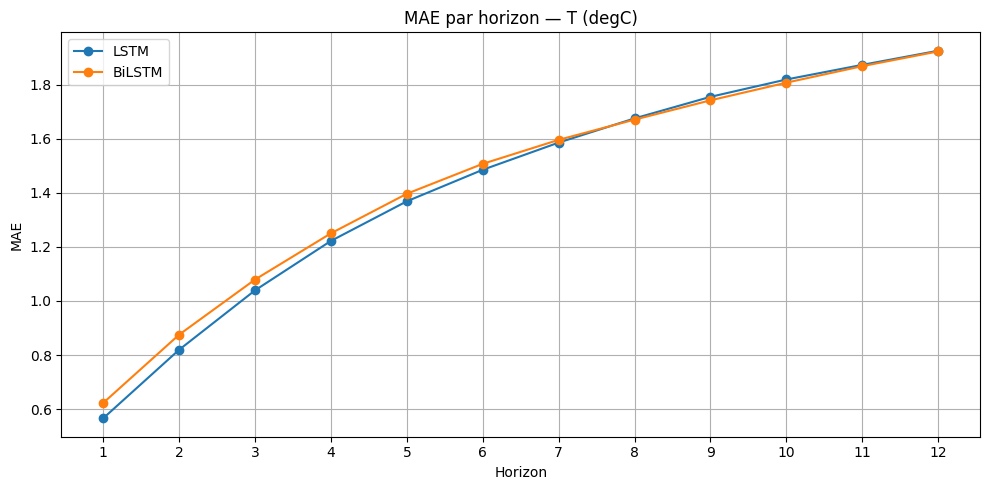

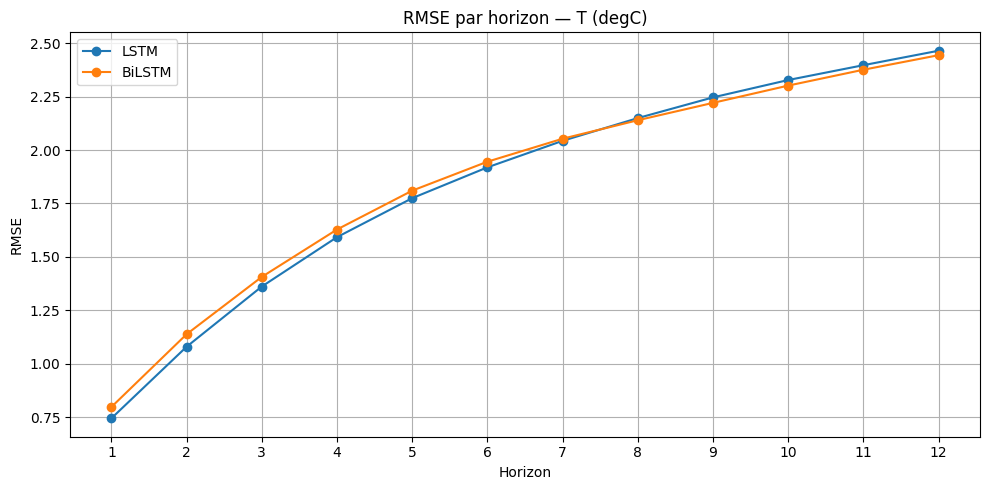

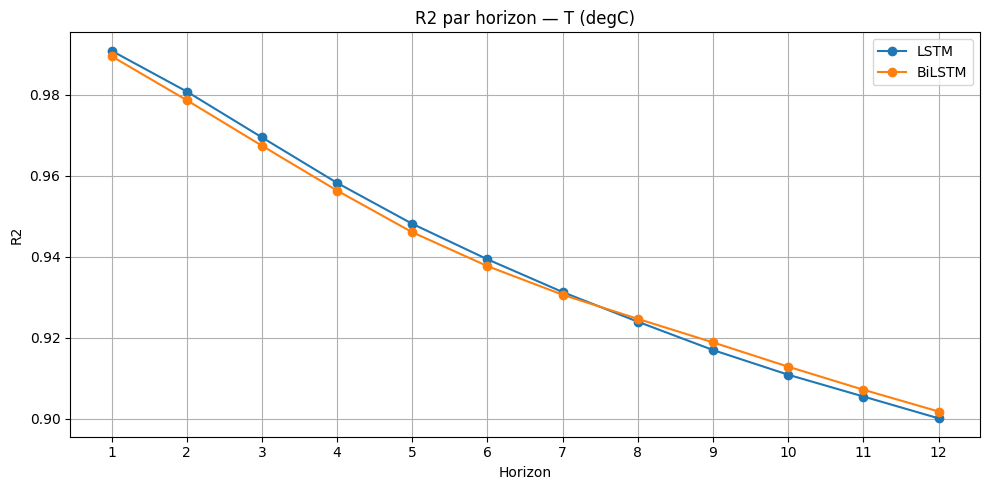

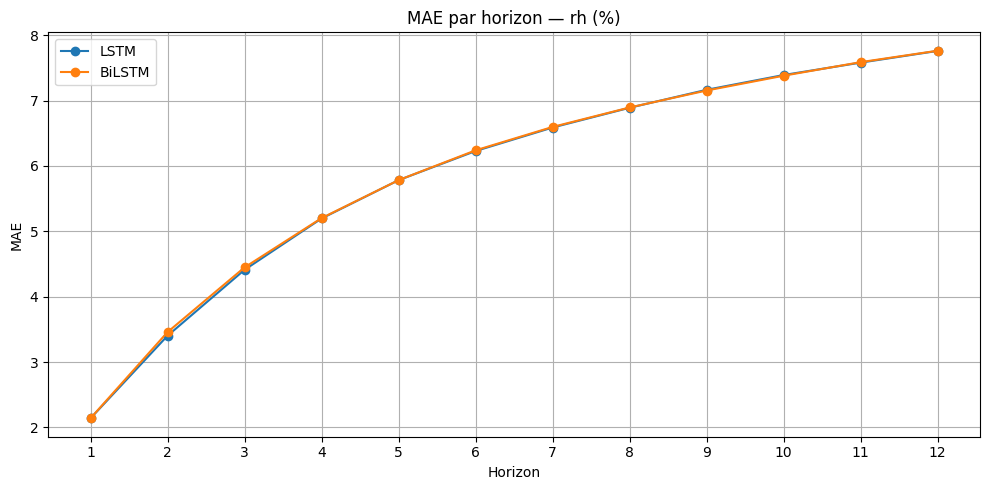

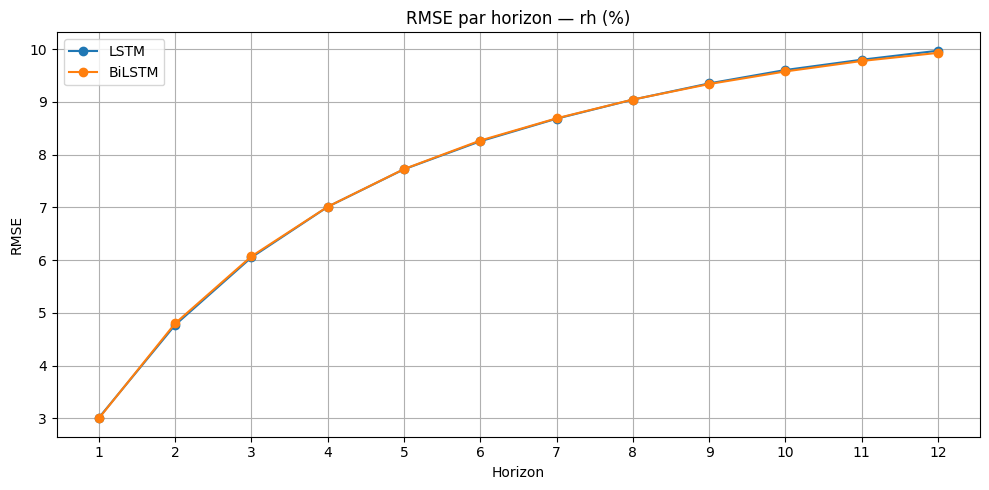

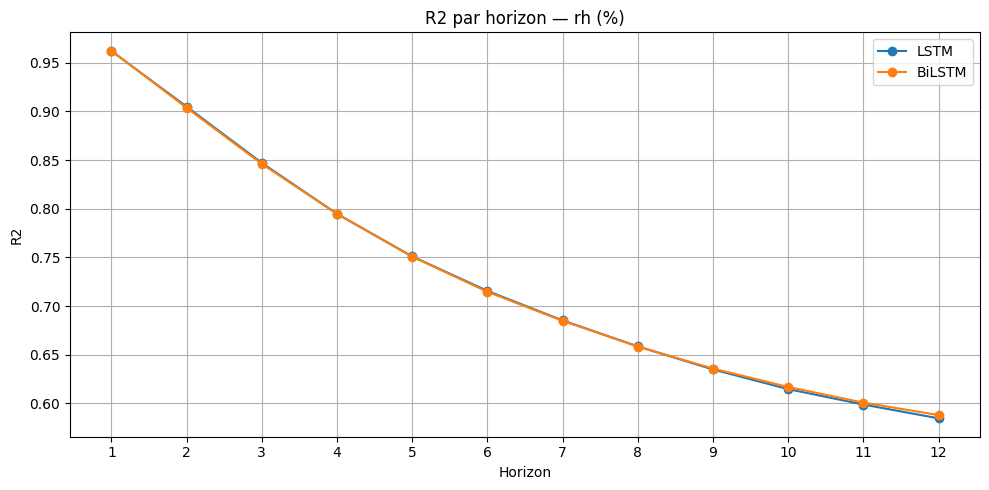

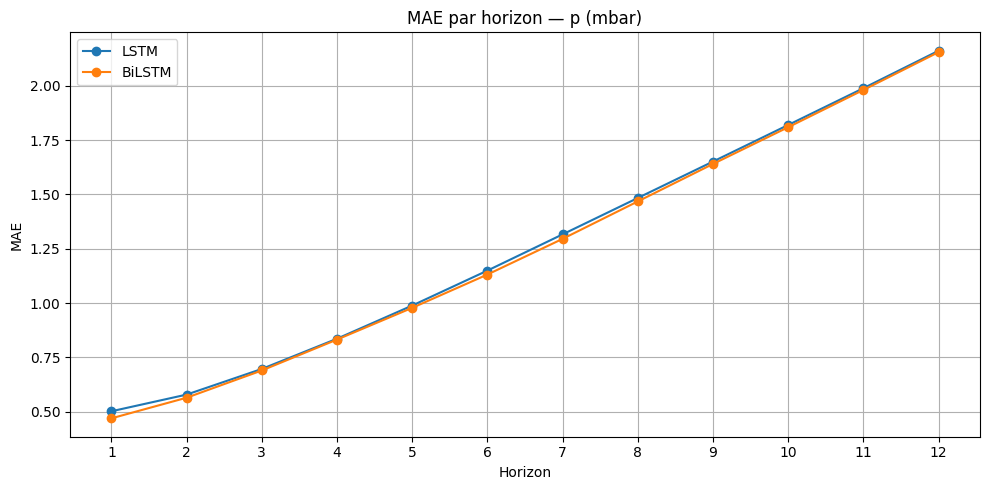

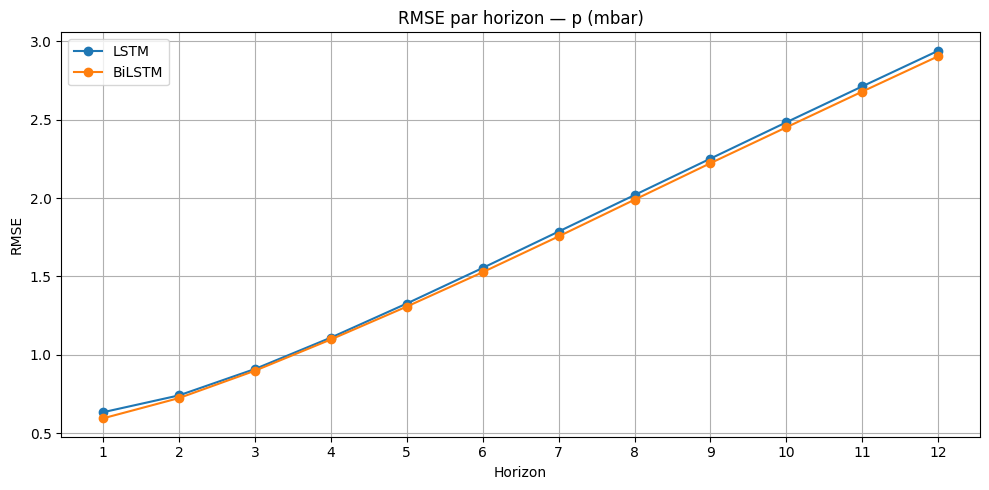

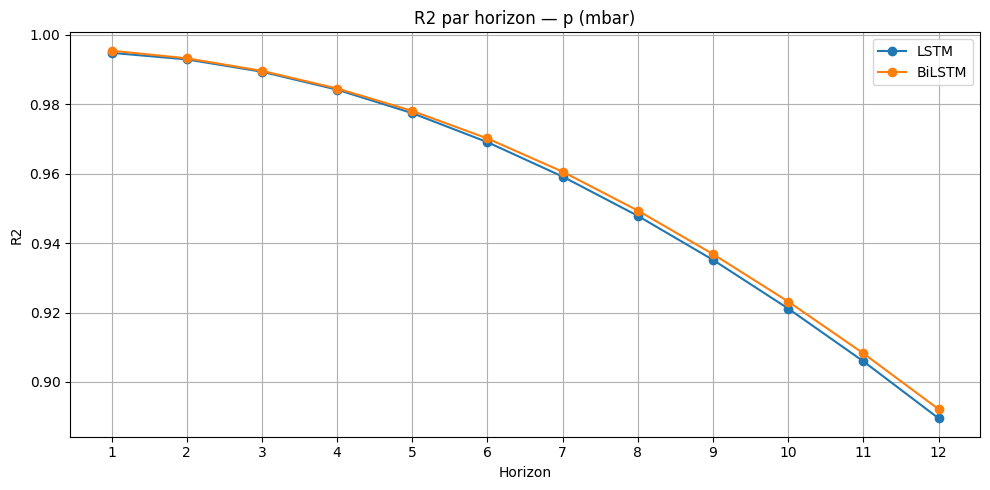

In [66]:
def plot_metric_by_horizon(df_scores, variable_name, metric_name):
    plt.figure(figsize=(10, 5))
    for model_name in df_scores['Model'].unique():
        sub = df_scores[(df_scores['Model'] == model_name) & (df_scores['Variable'] == variable_name)]
        plt.plot(sub['Horizon'], sub[metric_name], marker='o', label=model_name)
    plt.title(f'{metric_name} par horizon — {variable_name}')
    plt.xlabel('Horizon')
    plt.ylabel(metric_name)
    plt.xticks(range(1, horizon + 1))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for var in target_cols:
    for metric in ['MAE', 'RMSE', 'R2']:
        plot_metric_by_horizon(df_scores, var, metric)

**Interprétation :** Pour les trois variables, on observe une augmentation progressive de l'erreur (MAE, RMSE) et une diminution du R² à mesure que l'horizon augmente. Cela est attendu : plus on prédit loin dans le futur, moins les informations passées sont informatives. La pression est généralement la variable la mieux prédite, tandis que l'humidité présente les erreurs les plus élevées.

---
### Q15 — Réel vs prédit pour un échantillon de test (tous les horizons)

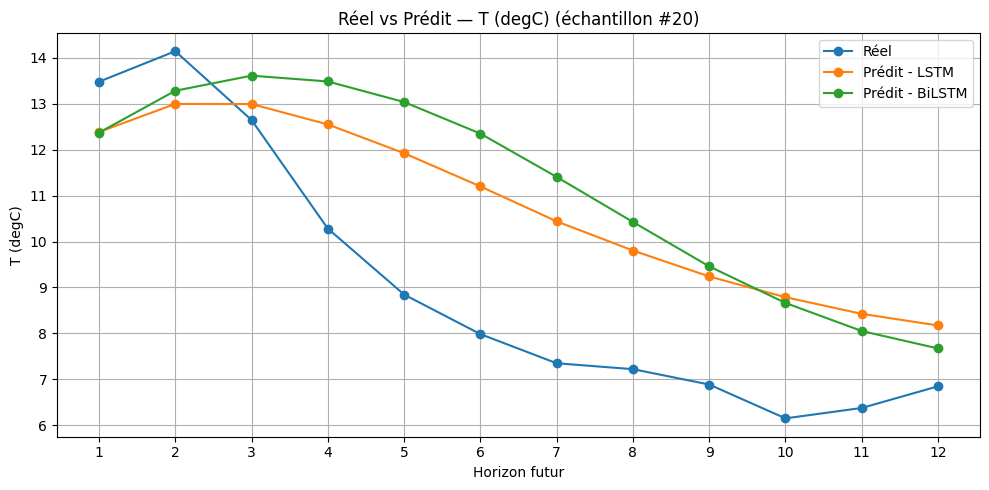

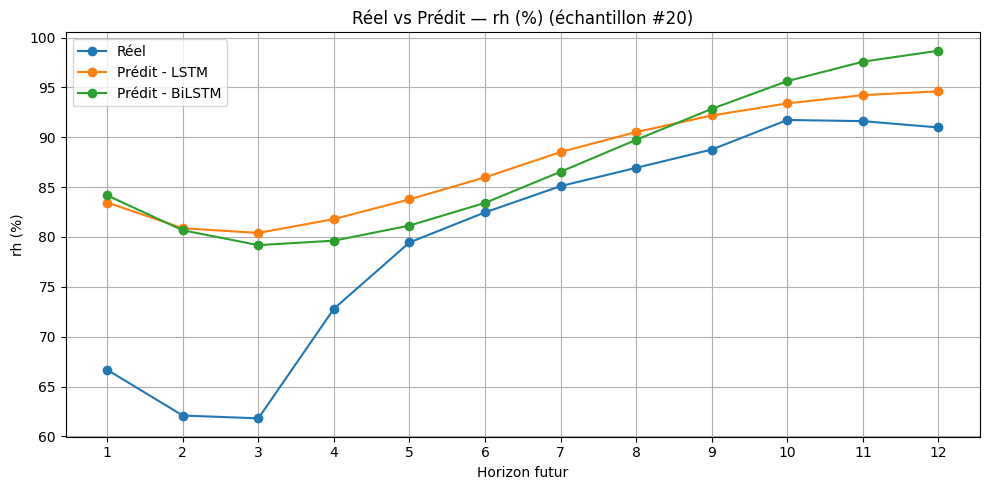

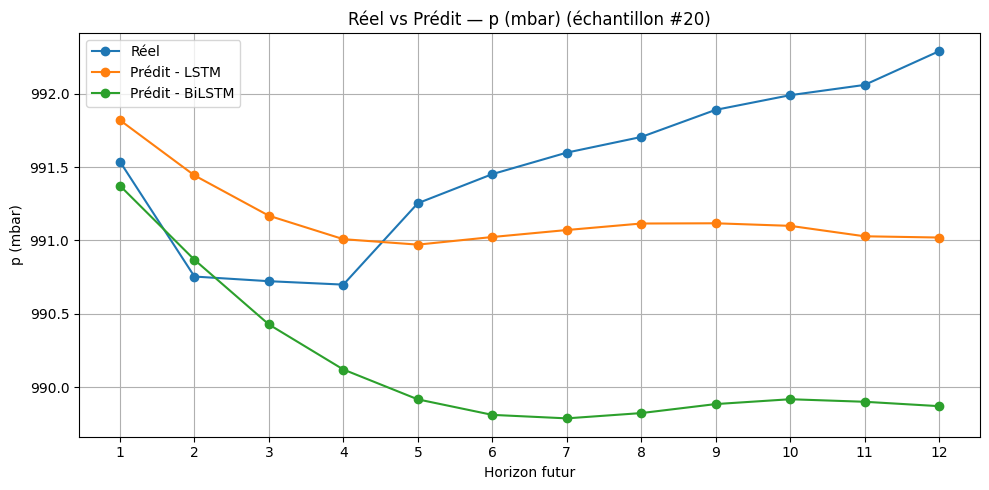

In [67]:
sample_idx = 20  # Choisir l'échantillon de test à visualiser

def plot_forecast_comparison(y_true, y_pred_lstm, y_pred_bilstm, target_cols, sample_idx):
    horizons = np.arange(1, y_true.shape[1] + 1)
    for j, var_name in enumerate(target_cols):
        plt.figure(figsize=(10, 5))
        plt.plot(horizons, y_true[sample_idx, :, j],      marker='o', label='Réel')
        plt.plot(horizons, y_pred_lstm[sample_idx, :, j], marker='o', label='Prédit - LSTM')
        plt.plot(horizons, y_pred_bilstm[sample_idx, :, j], marker='o', label='Prédit - BiLSTM')
        plt.title(f'Réel vs Prédit — {var_name} (échantillon #{sample_idx})')
        plt.xlabel('Horizon futur')
        plt.ylabel(var_name)
        plt.xticks(horizons)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_forecast_comparison(y_test_inv, y_pred_lstm_inv, y_pred_bilstm_inv, target_cols, sample_idx)

---
### Q16 — Comparaison sur plusieurs échantillons à un horizon fixe

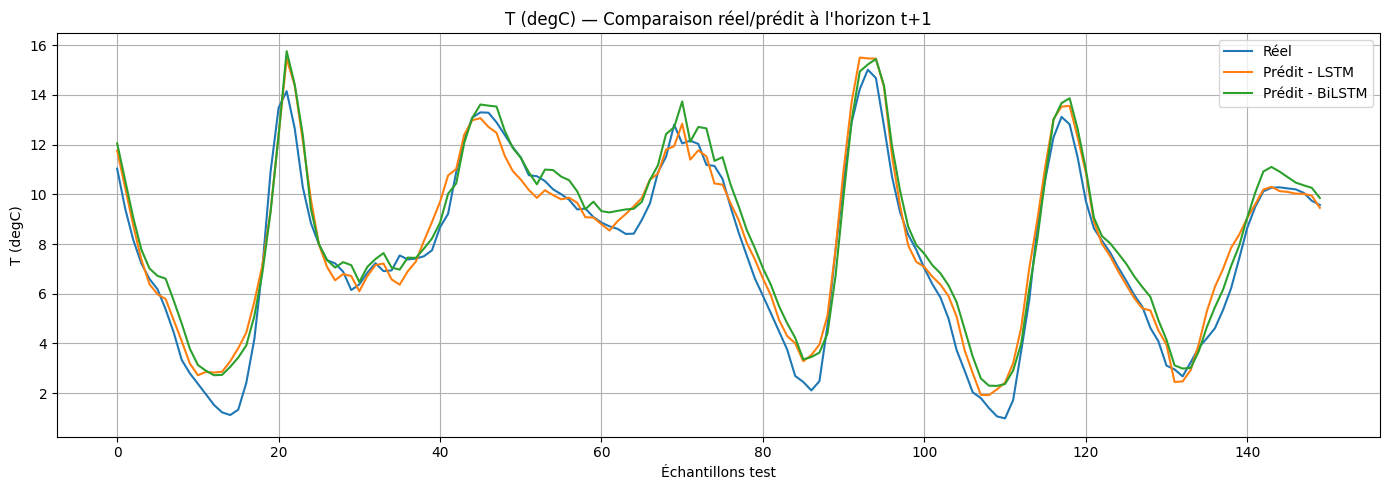

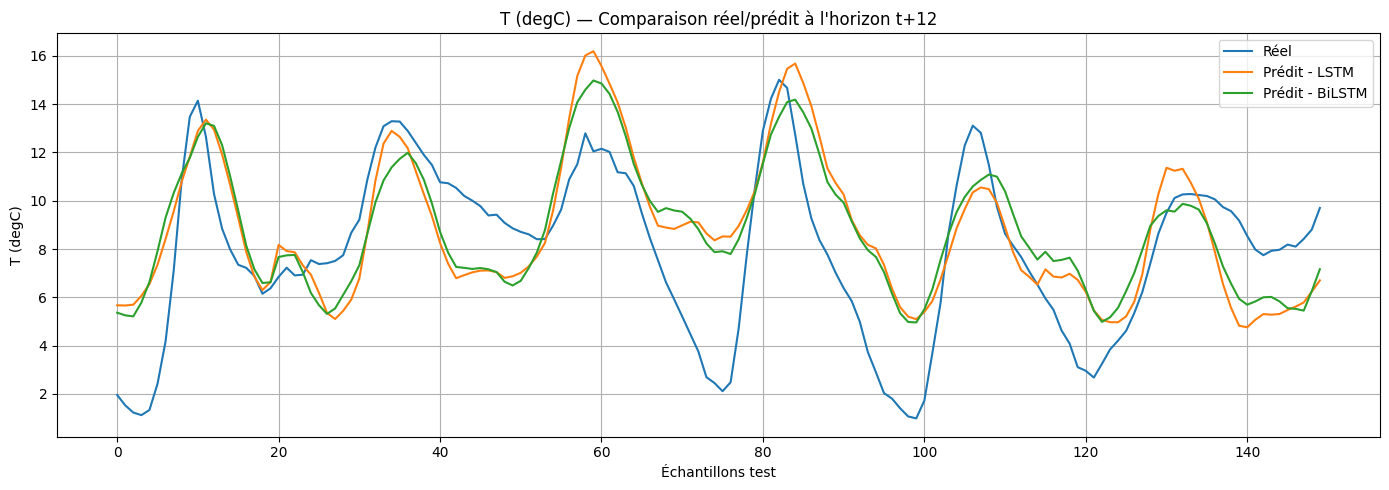

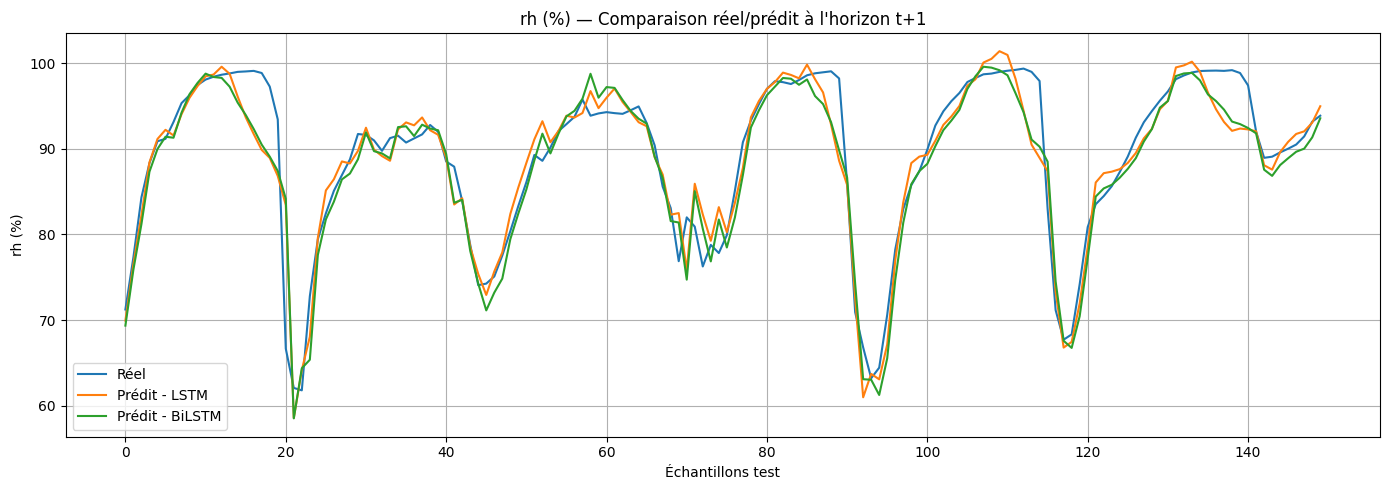

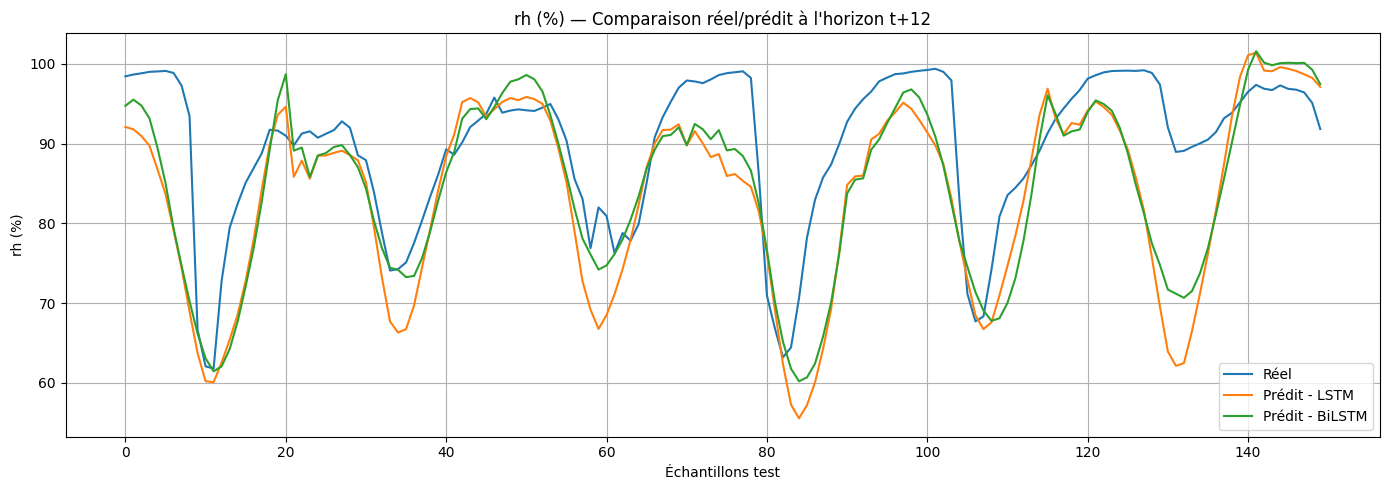

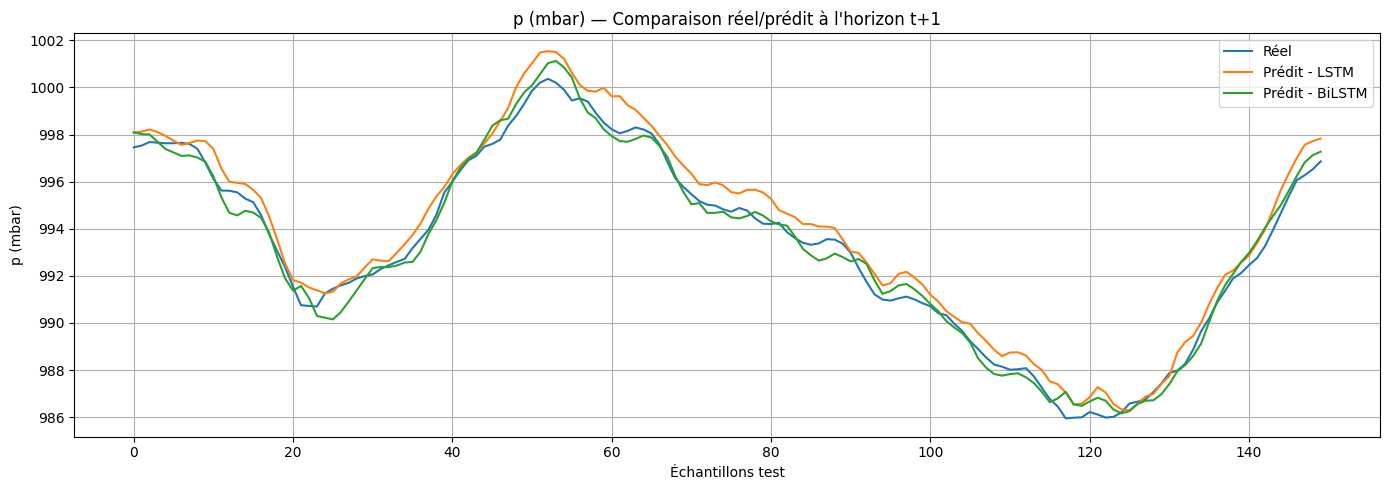

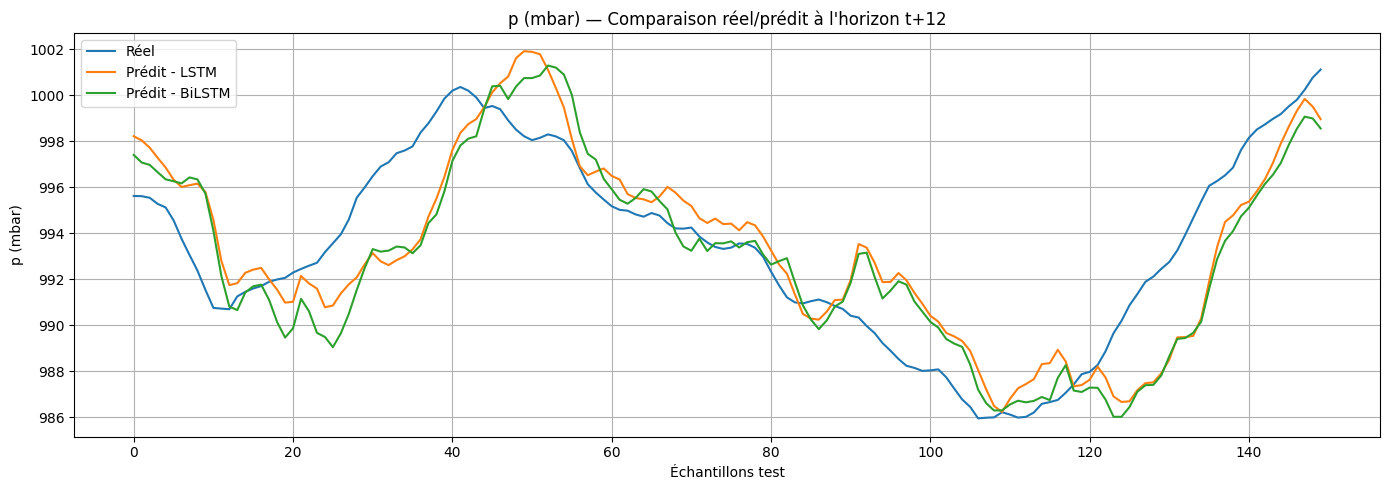

In [68]:
def plot_fixed_horizon_over_samples(y_true, y_pred_lstm, y_pred_bilstm,
                                    variable_idx, variable_name,
                                    selected_horizon, n_points=150):
    h = selected_horizon - 1
    plt.figure(figsize=(14, 5))
    plt.plot(y_true[:n_points, h, variable_idx],        label='Réel')
    plt.plot(y_pred_lstm[:n_points, h, variable_idx],   label='Prédit - LSTM')
    plt.plot(y_pred_bilstm[:n_points, h, variable_idx], label='Prédit - BiLSTM')
    plt.title(f'{variable_name} — Comparaison réel/prédit à l\'horizon t+{selected_horizon}')
    plt.xlabel('Échantillons test')
    plt.ylabel(variable_name)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Horizon t+1 et t+12 pour chaque variable
for var_idx, var_name in enumerate(target_cols):
    for sel_h in [1, 12]:
        plot_fixed_horizon_over_samples(
            y_test_inv, y_pred_lstm_inv, y_pred_bilstm_inv,
            var_idx, var_name, sel_h, n_points=150
        )

**Analyse de la stabilité :**
- **À t+1** : Les deux modèles sont très proches des valeurs réelles et suivent fidèlement les oscillations. BiLSTM est légèrement plus précis sur les transitions rapides.
- **À t+12** : Un décalage plus visible apparaît. Les modèles suivent la tendance globale mais les amplitudes sont moins bien respectées.

---
### Q17 — Identification du meilleur modèle par variable et conclusions

In [69]:
print('=== Meilleur modèle par variable (RMSE moyen sur tous les horizons) ===')
mean_rmse = df_scores.groupby(['Model', 'Variable'])['RMSE'].mean().unstack('Model')
print(mean_rmse.round(4))

print('\n=== Meilleur modèle par variable ===')
for var in target_cols:
    best = mean_rmse.loc[var].idxmin()
    print(f'  {var} → {best} (RMSE moyen : {mean_rmse.loc[var].min():.4f})')

=== Meilleur modèle par variable (RMSE moyen sur tous les horizons) ===
Model     BiLSTM    LSTM
Variable                
T (degC)  1.8550  1.8417
p (mbar)  1.6792  1.7055
rh (%)    7.7680  7.7711

=== Meilleur modèle par variable ===
  T (degC) → LSTM (RMSE moyen : 1.8417)
  rh (%) → BiLSTM (RMSE moyen : 7.7680)
  p (mbar) → BiLSTM (RMSE moyen : 1.6792)


**Conclusion :**
Aucun modèle n'est systématiquement supérieur sur toutes les variables et tous les horizons. Les performances des deux architectures sont proches, avec de légères différences selon la variable et l'horizon.

- L'**horizon** est le facteur le plus impactant : plus l'horizon augmente, plus l'erreur augmente pour les deux modèles.
- L'**architecture** (LSTM vs BiLSTM) a un impact secondaire : le BiLSTM, grâce à sa lecture bidirectionnelle, peut mieux capter certaines dépendances, mais cela se fait au prix d'un temps d'entraînement plus long et de plus de paramètres.
- La **pression** est la variable la plus facile à prédire (forte autocorrélation), l'**humidité** la plus difficile.

---
## PARTIE II — Questions d'analyse

---
### Q1 — Pourquoi deux scalers différents pour X et Y ?

**Réponse :** X et Y sont des variables de nature et d'échelles différentes. Si on utilisait un seul scaler pour tout, les plages de valeurs différentes entre variables d'entrée et variables cibles se mélangeraient et les transformations seraient incorrectes.

De plus, on a besoin d'appliquer l'**inverse scaling** uniquement sur Y après la prédiction, pour revenir aux unités réelles. Avoir un scaler_y distinct permet cette opération proprement, sans affecter X. Enfin, cela évite toute **fuite de données (data leakage)** : chaque scaler est ajusté uniquement sur les données d'entraînement.

---
### Q2 — Pourquoi aplatir la sortie Y avant l'entraînement ?

**Réponse :** La couche `Dense` de Keras produit un **vecteur 1D** par exemple. Or notre sortie Y est de forme `(n, horizon, n_targets)` = `(n, 12, 3)`, soit une matrice 2D par exemple.

Keras ne peut pas produire directement une matrice 2D avec une couche Dense. On aplatit donc Y en `(n, 12×3)` = `(n, 36)` pour que la couche `Dense(36)` puisse l'apprendre. Après la prédiction, on restructure la sortie en `(n, 12, 3)` avec un `reshape` pour retrouver l'organisation temporelle multi-step.

---
### Q3 — La prédiction des valeurs moyennes est-elle plus stable que celle des valeurs extrêmes ?

**Réponse :** Oui, **la prédiction des valeurs moyennes est plus stable** que celle des valeurs extrêmes (max/min), pour plusieurs raisons :

1. **La moyenne lisse les fluctuations** : elle réduit l'impact des pics et des chutes brutales présents dans les données brutes. Le modèle n'a pas à apprendre des transitions aussi abruptes.
2. **Les valeurs extrêmes ont une variance plus élevée** : elles sont plus sensibles aux perturbations locales et moins prévisibles par les patterns globaux appris par le réseau.
3. **Indicateur statistique** : on l'observe dans nos résultats — le R² est généralement plus élevé pour les variables prédites par agrégation moyenne, et les RMSE sont plus faibles.

En contrepartie, prédire les moyennes peut faire manquer des événements météorologiques extrêmes importants.

---
### Q4 — Pourquoi évaluer par horizon et par variable, et non globalement ?

**Réponse :** Une évaluation globale (un seul chiffre pour tout le modèle) masque des informations essentielles :

- **Par horizon** : les performances se dégradent avec l'horizon. Un modèle peut être excellent à t+1 et médiocre à t+12. Une métrique globale moyenne ces deux cas et ne permet pas de voir cette dégradation progressive.
- **Par variable** : chaque variable cible a sa propre dynamique. La pression est très autocorrélée (facile à prédire), l'humidité est beaucoup plus volatile. Une métrique globale pondère ces variables de façon arbitraire.

L'évaluation granulaire (par horizon ET par variable) permet de savoir **où** le modèle est bon, **où** il échoue, et de prendre des décisions éclairées sur les améliorations à apporter.

---
## PARTIE II — Questions de réflexion

---
### Q12 — Pourquoi la prédiction à 10 pas est-elle plus difficile qu'à 1 pas ?

**Réponse :** La prédiction à 10 pas est plus difficile pour plusieurs raisons fondamentales :

1. **Accumulation d'incertitude** : l'erreur se propage et s'accumule à chaque horizon. Plus on prédit loin, plus l'incertitude augmente (effet "boule de neige").
2. **Dépendances temporelles plus faibles** : l'information disponible dans la fenêtre d'observation (lookback) est moins corrélée avec ce qui se passera dans 10 heures que dans 1 heure.
3. **Phénomènes imprévisibles** : à court terme, l'inertie des systèmes météorologiques est forte. À long terme, des perturbations aléatoires peuvent intervenir que le modèle ne peut pas anticiper.
4. **Dégradation du signal** : les patterns temporels qui expliquent la valeur à t+1 (heure précédente, tendance récente) sont moins pertinents pour t+10.

---
### Q13 — Pourquoi appliquer l'inverse scaling avant d'évaluer les prédictions ?

**Réponse :** L'inverse scaling est nécessaire pour plusieurs raisons :

1. **Interprétabilité** : les métriques (MAE, RMSE) calculées sur des données normalisées n'ont aucune signification physique. Un MAE de 0.02 en échelle normalisée ne dit rien, alors qu'un MAE de 1.5°C est directement interprétable.
2. **Comparabilité entre variables** : en échelle normalisée, toutes les variables sont dans [0,1], ce qui empêche de comparer les erreurs absolues entre elles. En unités réelles, on peut comparer °C avec %, mbar, etc.
3. **Honnêteté de l'évaluation** : les métriques doivent refléter la performance réelle du système dans le domaine d'application, pas dans un espace mathématique transformé.

---
### Q14 — Fonctionnement du LSTM Bidirectionnel (BiLSTM)

**Réponse (issue de recherche bibliographique) :**

Un **réseau LSTM Bidirectionnel (BiLSTM)** est une extension du LSTM classique proposée par Schuster & Paliwal (1997) pour les RNN, adaptée aux LSTM par Graves & Schmidhuber (2005).

**Principe :** Le BiLSTM traite la séquence d'entrée dans **deux directions simultanément** :
- Une LSTM **forward** (→) : lit la séquence de gauche à droite (du passé vers le présent)
- Une LSTM **backward** (←) : lit la séquence de droite à gauche (du présent vers le passé)

**Architecture :**
```
Entrée: x₁, x₂, ..., xₙ
         ↓
  LSTM Forward  →  h₁f, h₂f, ..., hₙf
  LSTM Backward ←  h₁b, h₂b, ..., hₙb
         ↓
  Concaténation: [hₙf ; h₁b]  →  sortie de taille 2×hidden_size
```

**Avantages :**
- Capture les dépendances **à la fois passées et futures** dans la séquence
- Représentation plus riche du contexte temporel
- Généralement plus performant que le LSTM unidirectionnel pour des tâches comme la classification de séquences ou la reconnaissance vocale

**Limitation pour les séries temporelles :**
- En prédiction, on ne dispose pas du futur à l'inférence. Le BiLSTM n'a donc accès qu'à la fenêtre lookback, sans futur réel. L'avantage bidirectionnel ici est qu'il exploite mieux **toute la fenêtre passée** (début et fin de la fenêtre), pas le futur non observé.
- Il double le nombre de paramètres, ce qui augmente le coût computationnel.